# Tutorial: measuring proximity to criticality with $d_2$

> **NOT OWN WORK.** Python port of `demo/demo.mlx` from the MATLAB *prox_crit_toolkit* by J. S. Sooter et al. ([GitHub](https://github.com/sam-sooter/prox_crit_toolkit), fetched 2026-10-09; CC BY-NC 4.0), translated by Andre Potthoff (with Claude). Text and code follow the original cell by cell; additions are marked *[port note]*. Functions: `src/analysis/prox_crit/` (see `NOTICE.md`, `FLAGS.md`).

*[port note]* Differences to the MATLAB tutorial:
- Part 1 uses simulated data. MATLAB's `randn` stream cannot be reproduced, so the numbers differ slightly from the MATLAB printout, but they agree in distribution. The values MATLAB recorded are quoted for comparison.
- Part 2 uses real data. The spike-count series drop MATLAB's spurious last bin (CHANGED 5 in `FLAGS.md`), so $d_2$ differs from the MATLAB printout in the 4th digit, far below the error bars. With MATLAB's binning the printout is reproduced exactly (`tests/test_prox_crit.py`).
- The options struct `dbopt` becomes keyword arguments: `fit_method`, `with_err_bars`, `with_qc`, `with_parallel`. `with_parallel` is accepted, but the computation always runs sequentially.
- Figures and results are not saved; the `savefig` / `np.save` lines are commented out.

In [1]:
%load_ext jupyter_black
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from src.analysis.prox_crit import calc_db, run_ar, get_spike_counts, matlab_colon
from src.config.paths import FIGURES_DIR, RESULTS_OBJECTS

## Part 1: application to synthetic data

As a first example, we will calculate $d_2$ for a time series generated by an autoregressive (AR) model:

In [2]:
kern = [0.8, 0.2, -0.1]
sigma = 1  # AR model parameters
T = int(1e4)  # number of time steps
x = run_ar(kern, sigma, T, rng=np.random.default_rng(seed=0))  # simulate AR model
print(
    f"simulated AR({len(kern)}) series: {x.shape} {x.dtype}, mean {x.mean():.3f}, std {x.std():.3f}, first values {np.round(x[:5], 3)}"
)

# d2 settings (minimal)
order = 3  # AR model order
delta_t = 1  # time between consecutive steps in time series (in s)
b = 2  # calculate d2 (rather than d4, d6, ...)

dbopt = dict(
    with_err_bars=False,  # don't calculate error bars
    with_qc=False,  # don't make quality control plots
    with_parallel=False,  # don't use parallel computing
    fit_method="YuleWalker",  # AR fit method
)

result = calc_db(x, order, delta_t, b, **dbopt)
db, sddb, kern_fit, sigma_fit, H, kernc, exit_status = result

print(f"\ncalc_db returns a {type(result).__name__} with fields {result._fields}")
print(f"best-fit kernel: {np.array2string(kern_fit, precision=5)}  (true: {kern})")
print(
    f"best-fit noise sigma: {sigma_fit:.4f} (in units of the data's std, since the data are z-scored)"
)
print(
    f"closest critical kernel: {np.array2string(kernc, precision=5)}, its sum = {kernc.sum():.6f} (= 1 on M_2)"
)
print(
    f"d2 = {db:.5g} bits/s, error bar {sddb} (not requested), exit_status {exit_status}"
)
# MATLAB printout (different noise realization): best-fit kernel [0.80265 0.20848 -0.10767], d2 = 0.032682 bits/s

simulated AR(3) series: (10000,) float64, mean 0.063, std 2.359, first values [ 0.126 -0.032  0.64   0.598  0.074]

calc_db returns a DbResult with fields ('db', 'sddb', 'kern', 'sigma', 'H', 'kernc', 'exit_status')
best-fit kernel: [ 0.79924  0.2135  -0.10569]  (true: [0.8, 0.2, -0.1])
best-fit noise sigma: 0.4229 (in units of the data's std, since the data are z-scored)
closest critical kernel: [ 0.83888  0.22718 -0.06605], its sum = 1.000000 (= 1 on M_2)
d2 = 0.031283 bits/s, error bar nan (not requested), exit_status 0


Changing the AR fitting method to maximum likelihood doesn't change the measured $d_2$ value much:

In [3]:
dbopt["fit_method"] = "MaxLikelihood"
db, sddb, kern_fit, sigma_fit, H, kernc, exit_status = calc_db(
    x, order, delta_t, b, **dbopt
)
print(f"d2 = {db:.5g} bits/s, best-fit kernel {np.array2string(kern_fit, precision=5)}")
print(
    f"MaxLikelihood also returns the Hessian H of the log-likelihood, shape {H.shape}:\n{np.round(H, 1)}"
)
# MATLAB printout: d2 = 0.032694 bits/s

d2 = 0.031317 bits/s, best-fit kernel [ 0.79962  0.21317 -0.1058 ]
MaxLikelihood also returns the Hessian H of the log-likelihood, shape (3, 3):
[[-55903.6 -50499.2 -46954. ]
 [-50499.2 -55902.9 -50499.7]
 [-46954.  -50499.7 -55902.6]]


To double-check that the $d_2$ calculation was successful, we can visually inspect quality control plots:

2 panels: one per free coordinate of the critical kernel (order - b/2); d2 line at 0.031317 bits/s


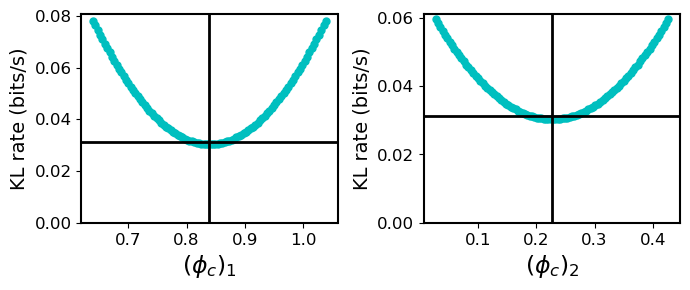

In [4]:
dbopt["with_qc"] = True
db, sddb, kern_fit, sigma_fit, H, kernc, exit_status = calc_db(
    x, order, delta_t, b, **dbopt
)
fig = plt.gcf()
fig.set_size_inches(7, 3)
# fig.savefig(FIGURES_DIR / "prox_crit_demo_qc.png", dpi=150, bbox_inches="tight")
print(
    f"{order - b // 2} panels: one per free coordinate of the critical kernel (order - b/2); d2 line at {db:.5g} bits/s"
)

These plots show how the KL divergence rate from the best-fit AR model to a critical AR model changes as the critical model is varied. Each panel corresponds to one component of the critical model's history kernel.

The $d_2$ calculation was successful if:
- the numerically calculated minimum in KL rate (where the black lines meet) matches the visual minimum in every panel, and
- the minimizer hasn't drifted outside of the set of critical AR models (in every panel, the black lines meet at a cyan, rather than red, point).

*[port note]* FLAG 6: the curves use a 1000-point trapezoid rule, while $d_2$ itself uses adaptive quadrature. The curve therefore sits about 1 % below the horizontal line, in MATLAB as well. The location of the minimum is what matters here.

Next, we will measure the uncertainty in $d_2$ given the observed time series:

In [5]:
dbopt["with_err_bars"] = True
dbopt["with_qc"] = False  # turn quality control plots off
db, sddb, kern_fit, sigma_fit, H, kernc, exit_status = calc_db(
    x, order, delta_t, b, **dbopt
)
print(
    f"d2 = {db:.5g} +- {sddb:.5g} bits/s  (relative uncertainty {sddb / db:.1%}, exit_status {exit_status})"
)
# MATLAB printout: d2 = 0.032694 +- 0.0016181 bits/s

d2 = 0.031317 +- 0.0015793 bits/s  (relative uncertainty 5.0%, exit_status 0)


This uncertainty metric is based on how well the observed data constrains the AR fit. If the maximum likelihood AR model is not much more likely (given the observed data) than other AR models with different values of $d_2$, then the uncertainty in $d_2$ is high.

The duration of the time series, in particular, strongly affects the uncertainty in $d_2$:

T =     50 steps: sddb = 0.0353 bits/s
T =     90 steps: sddb = 0.0202 bits/s
T =    162 steps: sddb = 0.0165 bits/s
T =    292 steps: sddb = 0.0114 bits/s
T =    527 steps: sddb = 0.0078 bits/s
T =    949 steps: sddb = 0.0059 bits/s
T =   1710 steps: sddb = 0.0039 bits/s
T =   3081 steps: sddb = 0.0030 bits/s
T =   5550 steps: sddb = 0.0022 bits/s
T =  10000 steps: sddb = 0.0016 bits/s


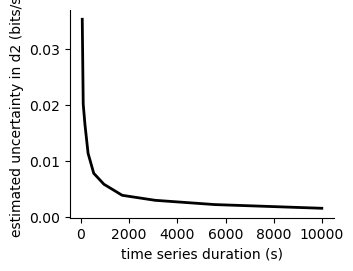

In [6]:
Tlist = np.round(np.logspace(np.log10(50), np.log10(T), 10)).astype(
    int
)  # durations to try
sddb_T = np.zeros(len(Tlist))
for Tidx, Tn in enumerate(Tlist):
    sddb_T[Tidx] = np.real(calc_db(x[:Tn], order, delta_t, b, **dbopt).sddb)
    print(f"T = {Tn:6d} steps: sddb = {sddb_T[Tidx]:.4f} bits/s")

fig, ax = plt.subplots(figsize=(3.4, 2.7))
ax.plot(Tlist, sddb_T, "k", linewidth=2)
ax.set_xlabel("time series duration (s)")
ax.set_ylabel("estimated uncertainty in d2 (bits/s)")
ax.spines[["top", "right"]].set_visible(False)
# fig.savefig(FIGURES_DIR / "prox_crit_demo_sddb_vs_T.png", dpi=150, bbox_inches="tight")

This makes sense: observing the dynamics for longer makes our measurement of proximity to criticality more reliable.

## Part 2: application to electrophysiological data

Here we will measure $d_2$ from single-unit extracellular electrophysiological recordings in visual cortex of freely-behaving mice (Senzai et al., *Neuron* 2019). Along the way, we will highlight some important methodological choices that affect $d_2$.

First, load the data. *[port note]* `load_ymv15` reads `data/external/senzai2019_YMV15.mat` (a copy of `demo/ephys_data/YMV15.mat`) into two tables; `notebooks/senzai2019_data_overview.ipynb` explores the data in detail.

In [7]:
from src.utils.senzai2019 import load_ymv15

spikes, states = load_ymv15()
st = spikes["time_s"].to_numpy()  # spike times (s), all units pooled
WAKE, NREM, REM = (
    states.loc[states["state"] == s, ["start_s", "end_s"]].to_numpy()
    for s in ("WAKE", "NREM", "REM")
)

print(
    f"st: {st.shape} {st.dtype}, {st.min():.2f} to {st.max():.2f} s; {spikes['unit'].nunique()} units"
)
for name, episodes in (("WAKE", WAKE), ("NREM", NREM), ("REM", REM)):
    print(
        f"{name}: {episodes.shape} array of [start, end] in s, {len(episodes)} episodes, {np.sum(episodes[:, 1] - episodes[:, 0]):.0f} s total"
    )

st: (7850337,) float64, 0.00 to 22441.96 s; 72 units
WAKE: (5, 2) array of [start, end] in s, 5 episodes, 3258 s total
NREM: (52, 2) array of [start, end] in s, 52 episodes, 10859 s total
REM: (15, 2) array of [start, end] in s, 15 episodes, 1224 s total


The array `st` contains spike times (in units of seconds), and the `unit` column identifies which neurons fired them. `WAKE`, `NREM`, and `REM` contain time windows in which the animal was in each of these behavioral states.

To calculate $d_2$, we first need to convert spikes to a time series. The simplest way to do this is to split the session into equally spaced time bins and count the number of spikes in each bin:

In [8]:
delta_t = 0.04  # time bin length (in seconds)
x = get_spike_counts(st, st.min(), st.max(), delta_t)  # make spike-count time series
print(
    f"spike-count series: {x.size:,} bins of {delta_t * 1000:.0f} ms; counts per bin mean {x.mean():.1f}, std {x.std():.1f}, max {x.max():.0f}"
)

# d2 settings
order = 5
b = 2
dbopt = dict(
    with_err_bars=True, with_qc=False, with_parallel=False, fit_method="MaxLikelihood"
)

# calculate d2
db, sddb, kern_fit, sigma_fit, H, kernc, exit_status = calc_db(
    x, order, delta_t, b, **dbopt
)
print(
    f"\nbest-fit kernel (lags 1-{order}, i.e. {delta_t * 1000:.0f}-{order * delta_t * 1000:.0f} ms): {np.array2string(kern_fit, precision=3)}"
)
print(f"closest critical kernel: {np.array2string(kernc, precision=3)}")
print(f"d2 = {db:.5g} +- {sddb:.5g} bits/s (exit_status {exit_status})")
# MATLAB printout: d2 = 1.7122 +- 0.0081069 bits/s

spike-count series: 561,049 bins of 40 ms; counts per bin mean 14.0, std 10.0, max 70

best-fit kernel (lags 1-5, i.e. 40-200 ms): [ 0.683 -0.165  0.031 -0.013  0.103]
closest critical kernel: [ 0.793 -0.125  0.091  0.028  0.213]
d2 = 1.7122 +- 0.0081069 bits/s (exit_status 0)


This $d_2$ value was calculated using the entire recording session, with periods of WAKE, NREM, and REM all thrown together. However, the dynamical state of the brain fluctuates dramatically over time, especially as the animal transitions between behavioral states.

We will therefore next calculate $d_2$ separately for WAKE, NREM, and REM:

In [9]:
# curate spike-count time series for each behavioral state (one segment per episode)
states_list = [WAKE, NREM, REM]
labels = ["WAKE", "NREM", "REM"]
x_states = [
    [get_spike_counts(st, t1, t2, delta_t) for t1, t2 in episodes]
    for episodes in states_list
]

# calculate d2 for each state
for label, segments in zip(labels, x_states):
    db, sddb, kern_fit, sigma_fit, H, kernc, exit_status = calc_db(
        segments, order, delta_t, b, **dbopt
    )
    lengths = [len(seg) for seg in segments]
    print(
        f"d2 ({label}) = {db:.5g} +- {sddb:.5g} bits/s   [{len(segments)} segments, {min(lengths)}-{max(lengths)} bins each]"
    )
# MATLAB printout: WAKE 1.0092 +- 0.015695 | NREM 2.5523 +- 0.0149 | REM 1.4795 +- 0.032053

d2 (WAKE) = 1.0097 +- 0.015697 bits/s   [5 segments, 6625-26050 bins each]
d2 (NREM) = 2.5518 +- 0.0149 bits/s   [52 segments, 250-13325 bins each]
d2 (REM) = 1.4805 +- 0.032028 bits/s   [15 segments, 25-5150 bins each]


To take this a step further, we can calculate $d_2$ in a short sliding window. To reduce run time, we will turn the `with_err_bars` option off. However, exploring the tradeoff between the time resolution of $d_2$ and the uncertainty in $d_2$ is a good exercise, and a recommended step when applying $d_2$ to your own data.

This code block usually takes about 5 minutes to run (*[port note]* about 4 minutes in Python).

747 windows of 60 s (1500 bins each), sliding by 30 s
d2 over windows: mean 2.14, median 2.27, range 0.68-4.89 bits/s, failed (nan): 0


(0.0, 18564.0)

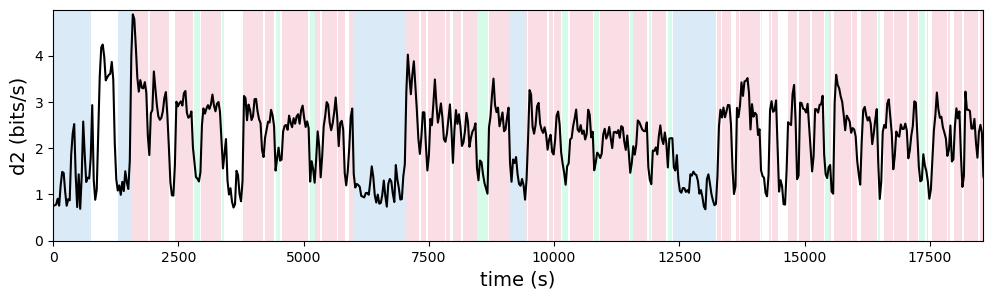

In [10]:
T_win = 60  # window duration (in s)
slide = 30  # slide between consecutive windows

dbopt["with_err_bars"] = False  # to save time, don't calculate error bars

# calculate d2 in sliding window
start = matlab_colon(st.min(), slide, st.max() - T_win)
d2 = np.zeros(len(start))
for i, s0 in enumerate(start):
    x = get_spike_counts(st, s0, s0 + T_win, delta_t)
    d2[i] = calc_db(x, order, delta_t, b, **dbopt).db
# np.save(RESULTS_OBJECTS / "prox_crit_demo_sliding_d2.npy", np.c_[start + T_win / 2, d2])
print(
    f"{len(start)} windows of {T_win} s ({int(T_win / delta_t)} bins each), sliding by {slide} s"
)
print(
    f"d2 over windows: mean {d2.mean():.2f}, median {np.median(d2):.2f}, range {d2.min():.2f}-{d2.max():.2f} bits/s, failed (nan): {np.isnan(d2).sum()}"
)

# plot results
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(start + T_win / 2, d2, "k", linewidth=1.5)

# annotate by sleep state
colors = np.array([[71, 158, 215], [230, 94, 132], [52, 235, 149]]) / 255
for idx, episodes in enumerate(states_list):
    for t1, t2 in episodes:
        ax.fill(
            [t1, t2, t2, t1],
            [0, 0, d2.max() + 0.1, d2.max() + 0.1],
            color=colors[idx],
            alpha=0.2,
            edgecolor="none",
        )
ax.set_xlabel("time (s)", fontsize=14)
ax.set_ylabel("d2 (bits/s)", fontsize=14)
ax.set_ylim(0, d2.max() + 0.1)
ax.set_xlim(0, max(episodes.max() for episodes in states_list))
# fig.savefig(FIGURES_DIR / "prox_crit_demo_sliding_d2.png", dpi=150, bbox_inches="tight")

*[port note]* Window starts and bin edges use `matlab_colon`, an exact replica of MATLAB's `a:d:b`. With `np.arange` the edges differ by ~1e-12, which moves spikes that sit exactly on an edge into the neighboring bin (see its docstring).

We made three key methodological choices to generate this plot:
- the time bin length `deltaT` for converting spikes to a spike-count time series,
- the AR model order `order`, and
- the duration `T` of the sliding window.

There is no one-size-fits-all procedure for selecting the values of these parameters, and in general you should vary them over a broad range to check the robustness of your results. However, here are a few tips to keep in mind:
- `deltaT` should be at least as long as the mean interspike interval (ISI). Otherwise, the spike count time series will consist mostly of 0s and 1s, which isn't good for AR model fitting.
- If the estimated uncertainty in $d_2$ is comparable in size to the actual $d_2$ value, then you should increase `T`.
- `deltaT` and `order` should be held fixed across different experimental conditions (such as sleep vs. wake) for fair comparisons.
- The total temporal reach of the AR model (`deltaT` × `order`) usually matters more for $d_2$ than either `deltaT` or `order` individually. This makes it reasonable to, for example, fix `deltaT` and vary `order` on a first pass through your data.
- In some simple models, the ground-truth distance to criticality can be calculated and compared to measured $d_2$ values. There, the agreement is usually best when `deltaT` × `order` matches the built-in interaction timescale of the model (Sooter et al., TBD). This suggests that the choice of `deltaT` × `order` for real neural data could be guided by known biophysical time constants, though nailing down a specific number is challenging in practice.

The auxiliary functions used by this demo (`runAR` → `run_ar`, `get_spike_counts`) live in `src/analysis/prox_crit/ar.py` and `src/analysis/prox_crit/spike_counts.py`.